# 01 · Exploratory data analysis

Get to know both datasets before choosing preprocessing or models. Every decision later in the project should be justified by something found here.

Questions to answer:
1. How big is each dataset, and what type is each column?
2. Are there missing values, duplicates, typos or odd codes?
3. How imbalanced is the target?
4. Which features look related to diabetes?

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.data import BRFSS_CLASSES, BRFSS_TARGET, D2019_TARGET, load_brfss, load_diabetes_2019

FIG_DIR = ROOT / 'reports' / 'figures'
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

## Dataset 1 · BRFSS 2015 diabetes health indicators

In [2]:
brfss = load_brfss()
print(brfss.shape)
brfss.head()

(253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1,1,1,40,1,0,0,0,0,1,0,1,0,5,18,15,1,0,9,4,3
1,0,0,0,0,25,1,0,0,1,0,0,0,0,1,3,0,0,0,0,7,6,1
2,0,1,1,1,28,0,0,0,0,1,0,0,1,1,5,30,30,1,0,9,4,8
3,0,1,0,1,27,0,0,0,1,1,1,0,1,0,2,0,0,0,0,11,3,6
4,0,1,1,1,24,0,0,0,1,1,1,0,1,0,2,3,0,0,0,11,5,4


In [3]:
brfss.describe().T

,count,mean,std,min,25%,50%,75%,max
Diabetes_012,253680.0,0.296921,0.698160,0.0,0.0,0.0,0.0,2.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


### Missing values and duplicates

In [4]:
print('Missing values:', brfss.isna().sum().sum())
dups = brfss.duplicated().sum()
print(f'Duplicate rows: {dups} ({dups / len(brfss):.1%})')

Missing values: 0
Duplicate rows: 23899 (9.4%)


> **Note for later:** decide what to do with duplicate rows. In survey data, two different people can give identical answers, so duplicates aren't necessarily errors. They do matter for the train/test split, though.

### Target balance

Diabetes_012
No diabetes    213703
Diabetes        35346
Prediabetes      4631
Name: count, dtype: int64 

Diabetes_012
No diabetes    0.842
Diabetes       0.139
Prediabetes    0.018
Name: count, dtype: float64


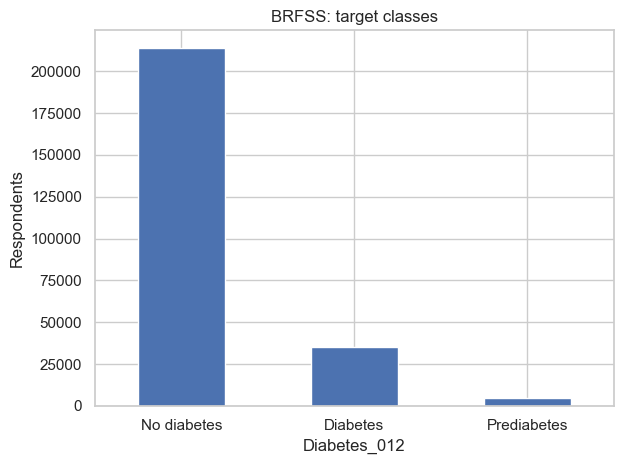

In [5]:
counts = brfss[BRFSS_TARGET].map(BRFSS_CLASSES).value_counts()
print(counts, '\n')
print((counts / counts.sum()).round(3))

ax = counts.plot.bar(rot=0, title='BRFSS: target classes')
ax.set_ylabel('Respondents')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_brfss_target.png', dpi=150); plt.show()

### How each feature relates to the target

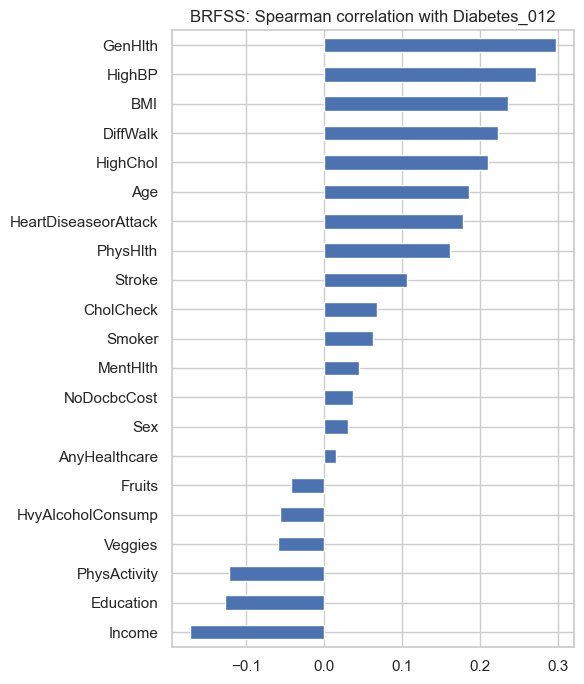

In [6]:
rates = {}
for col in brfss.columns.drop(BRFSS_TARGET):
    rates[col] = brfss.groupby(col)[BRFSS_TARGET].apply(lambda s: (s == 2).mean())

corr = brfss.corr(method='spearman')[BRFSS_TARGET].drop(BRFSS_TARGET).sort_values()
ax = corr.plot.barh(figsize=(6, 7), title='BRFSS: Spearman correlation with Diabetes_012')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_brfss_correlation.png', dpi=150); plt.show()

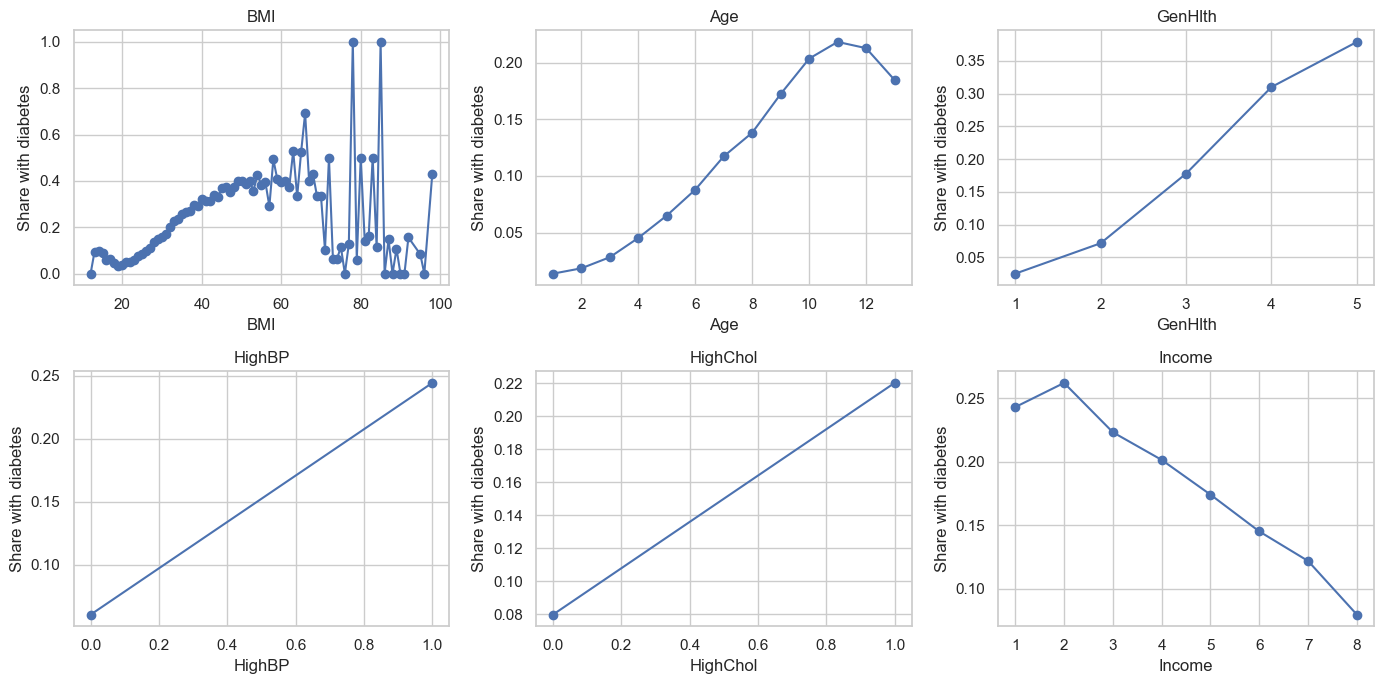

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, ['BMI', 'Age', 'GenHlth', 'HighBP', 'HighChol', 'Income']):
    rates[col].plot(ax=ax, marker='o', title=col)
    ax.set_ylabel('Share with diabetes')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_brfss_feature_rates.png', dpi=150); plt.show()

## Dataset 2 · Diabetes 2019 (Tigga & Garg)

In [8]:
d19 = load_diabetes_2019()
print(d19.shape)
d19.head()

(952, 18)


,Age,Gender,Family_Diabetes,highBP,PhysicallyActive,BMI,Smoking,Alcohol,Sleep,SoundSleep,RegularMedicine,JunkFood,Stress,BPLevel,Pregancies,Pdiabetes,UriationFreq,Diabetic
0,50-59,male,no,yes,one hr or more,39.0,no,no,8,6,no,occasionally,sometimes,high,0.0,0,not much,no
1,50-59,male,no,yes,less than half an hr,28.0,no,no,8,6,yes,very often,sometimes,normal,0.0,0,not much,no
2,40-49,male,no,no,one hr or more,24.0,no,no,6,6,no,occasionally,sometimes,normal,0.0,0,not much,no
3,50-59,male,no,no,one hr or more,23.0,no,no,8,6,no,occasionally,sometimes,normal,0.0,0,not much,no
4,40-49,male,no,no,less than half an hr,27.0,no,no,8,8,no,occasionally,sometimes,normal,0.0,0,not much,no


In [9]:
d19.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 952 entries, 0 to 951
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               952 non-null    object 
 1   Gender            952 non-null    object 
 2   Family_Diabetes   952 non-null    object 
 3   highBP            952 non-null    object 
 4   PhysicallyActive  952 non-null    object 
 5   BMI               948 non-null    float64
 6   Smoking           952 non-null    object 
 7   Alcohol           952 non-null    object 
 8   Sleep             952 non-null    int64  
 9   SoundSleep        952 non-null    int64  
 10  RegularMedicine   952 non-null    object 
 11  JunkFood          952 non-null    object 
 12  Stress            952 non-null    object 
 13  BPLevel           952 non-null    object 
 14  Pregancies        910 non-null    float64
 15  Pdiabetes         951 non-null    object 
 16  UriationFreq      952 non-null    object 
 1

### Values in every column
Look for typos, inconsistent labels and impossible values.

In [10]:
for col in d19.columns:
    print(f'{col}: {d19[col].value_counts(dropna=False).to_dict()}')

Age: {'less than 40': 488, '40-49': 164, '50-59': 156, '60 or older': 144}
Gender: {'male': 580, 'female': 372}
Family_Diabetes: {'no': 498, 'yes': 454}
highBP: {'no': 724, 'yes': 228}
PhysicallyActive: {'less than half an hr': 336, 'more than half an hr': 272, 'one hr or more': 212, 'none': 132}
BMI: {24.0: 111, 21.0: 88, 23.0: 76, 28.0: 71, 26.0: 66, 33.0: 64, 27.0: 63, 22.0: 58, 20.0: 48, 19.0: 36, 25.0: 34, 30.0: 33, 18.0: 32, 29.0: 28, 38.0: 28, 36.0: 20, 32.0: 16, 31.0: 16, 17.0: 16, 35.0: 12, 34.0: 12, 15.0: 8, nan: 4, 39.0: 4, 40.0: 4, 42.0: 3, 45.0: 1}
Smoking: {'no': 844, 'yes': 108}
Alcohol: {'no': 760, 'yes': 192}
Sleep: {7: 264, 8: 256, 6: 256, 5: 68, 9: 48, 4: 32, 10: 24, 11: 4}
SoundSleep: {6: 228, 4: 188, 5: 156, 8: 120, 7: 104, 3: 68, 2: 44, 10: 16, 9: 16, 11: 4, 1: 4, 0: 4}
RegularMedicine: {'no': 615, 'yes': 336, 'o': 1}
JunkFood: {'occasionally': 672, 'often': 184, 'very often': 52, 'always': 44}
Stress: {'sometimes': 564, 'very often': 164, 'not at all': 136, 'alwa

### Missing values and duplicates

In [11]:
print(d19.isna().sum()[d19.isna().sum() > 0], '\n')
dups = d19.duplicated().sum()
print(f'Duplicate rows: {dups} ({dups / len(d19):.1%})')

BMI            4
Pregancies    42
Pdiabetes      1
Diabetic       1
dtype: int64 

Duplicate rows: 631 (66.3%)


### Target balance

Diabetic
no     685
yes    266
NaN      1
Name: count, dtype: int64 

Diabetic
no     0.720
yes    0.279
NaN    0.001
Name: count, dtype: float64


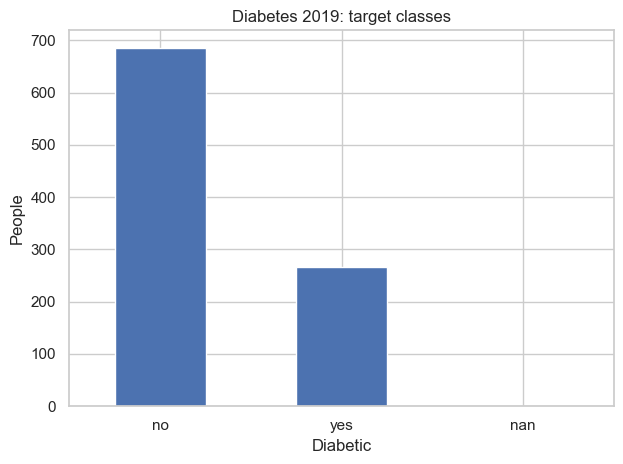

In [12]:
counts = d19[D2019_TARGET].value_counts(dropna=False)
print(counts, '\n')
print((counts / counts.sum()).round(3))

ax = counts.plot.bar(rot=0, title='Diabetes 2019: target classes')
ax.set_ylabel('People')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_d19_target.png', dpi=150); plt.show()

### How each feature relates to the target

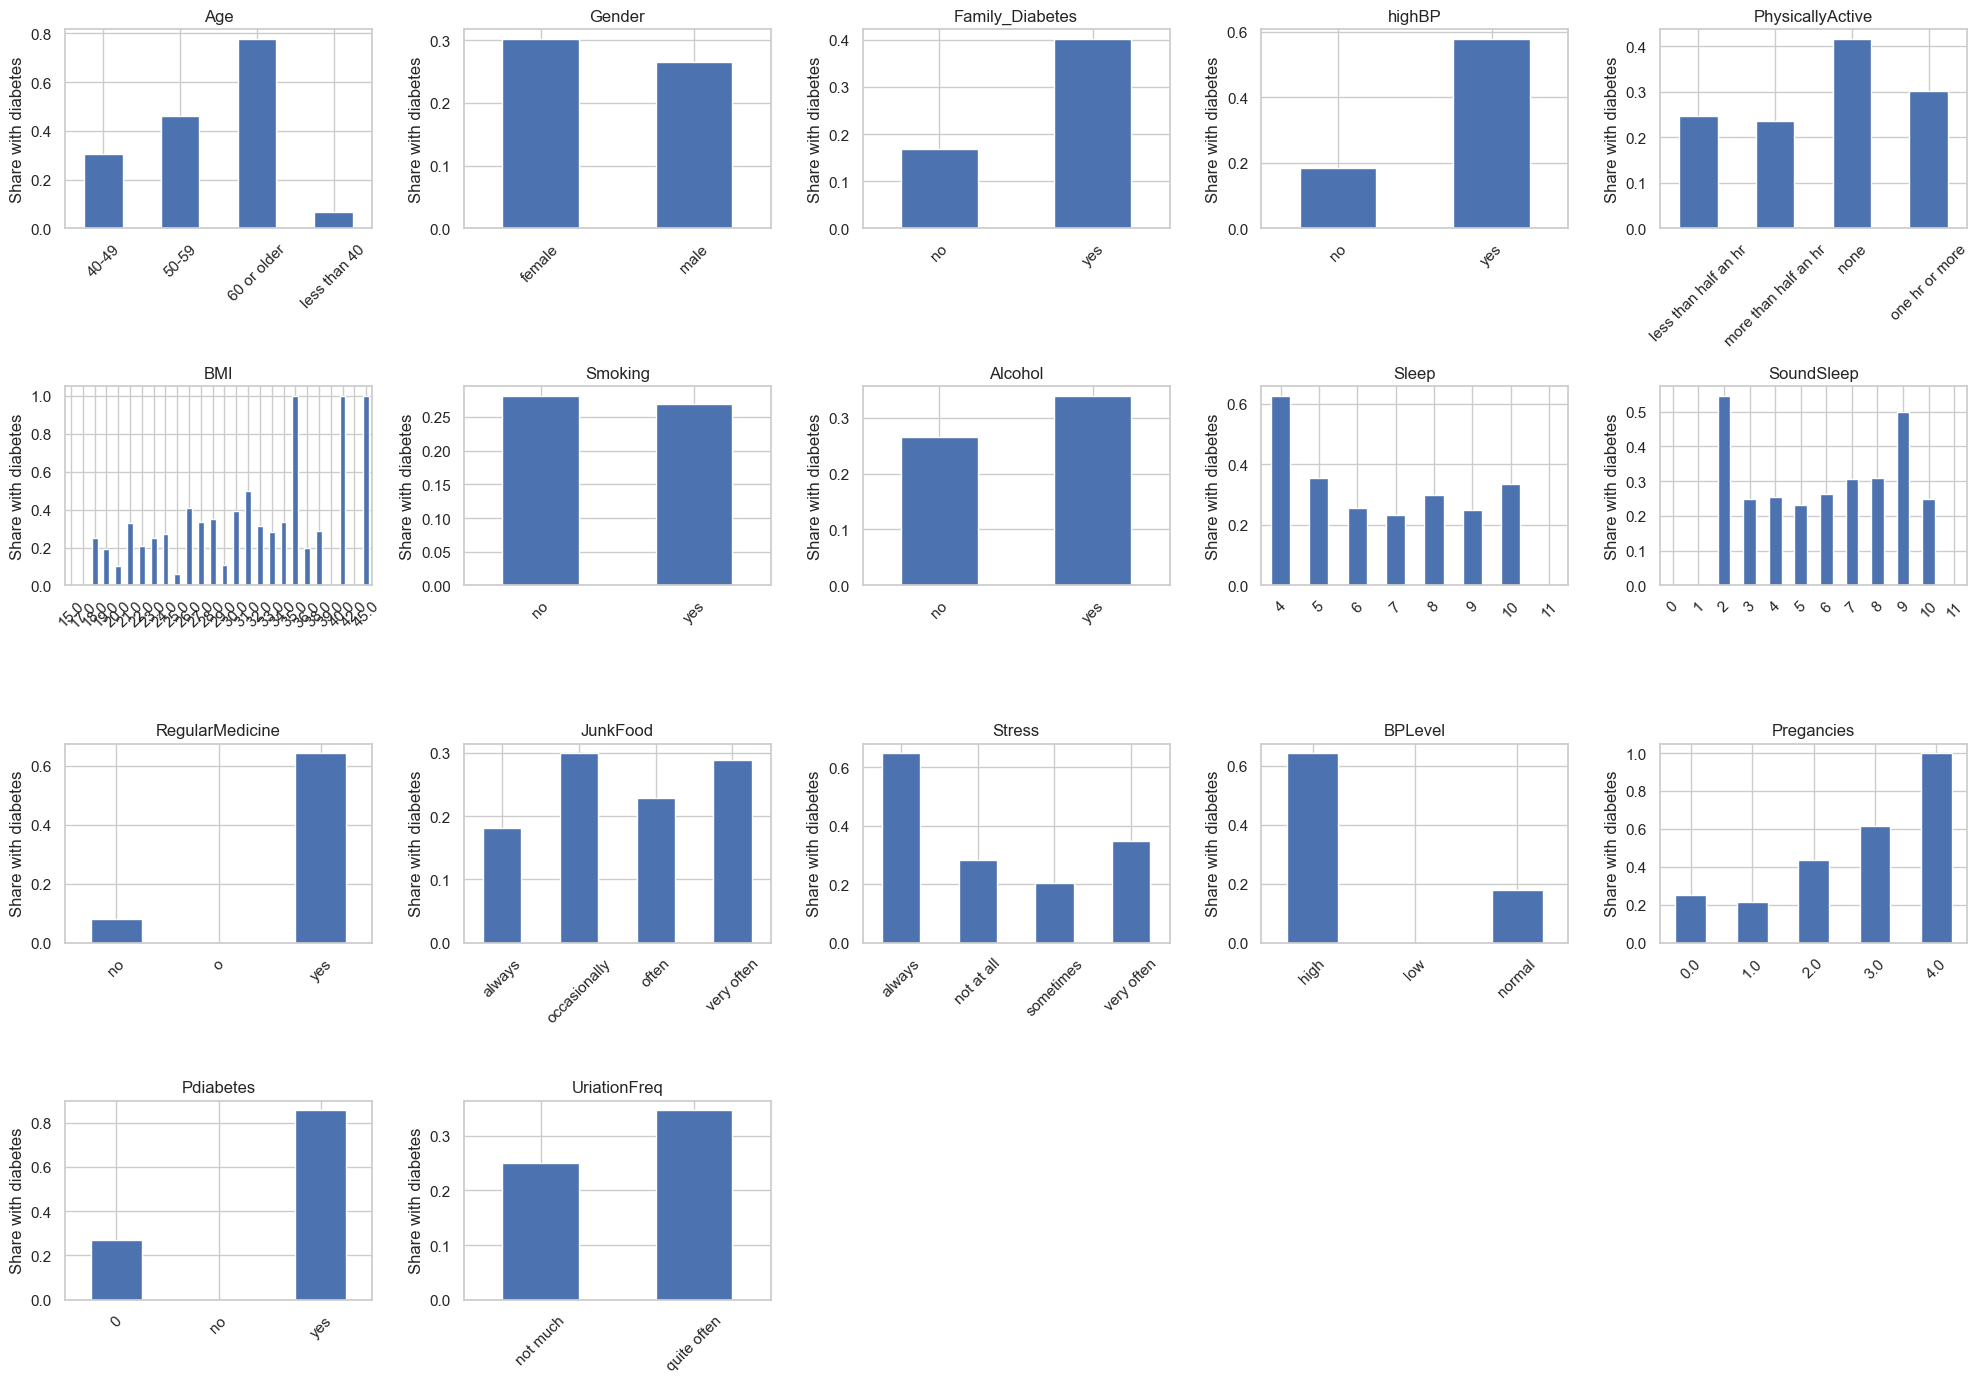

In [13]:
features = d19.columns.drop(D2019_TARGET)
fig, axes = plt.subplots(4, 5, figsize=(20, 14))
for ax, col in zip(axes.flat, features):
    pd.crosstab(d19[col], d19[D2019_TARGET], normalize='index').get('yes', pd.Series(dtype=float)) \
        .plot.bar(ax=ax, rot=45, title=col)
    ax.set_ylabel('Share with diabetes'); ax.set_xlabel('')
for ax in axes.flat[len(features):]:
    ax.axis('off')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_d19_feature_rates.png', dpi=150); plt.show()

### RegularMedicine: risk factor or consequence?

If almost everyone who takes regular medicine has diabetes, the feature probably reflects the diagnosis (people are treated *because* they have diabetes). That would make it leak the answer, and it couldn't be used in a tool meant to predict diabetes.

In [14]:
pd.crosstab(d19['RegularMedicine'], d19[D2019_TARGET], margins=True)

Diabetic,no,yes,All
RegularMedicine,,,
no,564,50,614
o,1,0,1
yes,120,216,336
All,685,266,951


## Findings and decisions

These decisions are **proposed**. Confirm them (or change them) with the team and supervisor before the preprocessing notebook.

### BRFSS 2015 (253,680 rows, 21 features, 3 classes)
| Finding | Proposed decision |
|---|---|
| No missing values. All columns are whole-number codes (binary, ordinal or counts). | No imputation. Use the ordinal codes as they are. Tree models don't need scaling, so scale only for models that do (KNN, logistic regression), inside a pipeline. |
| Very imbalanced: 84.2% no diabetes, 13.9% diabetes, **1.8% prediabetes** (4,631 rows). | Use a stratified split. Handle imbalance **on the training set only** (class weights or resampling, compared). Report macro-F1 and per-class recall, not just accuracy (predicting "no diabetes" for everyone already scores 84%). |
| 23,899 duplicate rows (9.4%). These are survey answers, and two different people can give the same coded answers. 1,834 identical feature combinations have *different* labels. | Keep the duplicates (they're plausibly real people), but don't create any new duplicates before the split. Note the label conflicts as a limit on how accurate any model can be. |
| GenHlth, HighBP, BMI, DiffWalk, HighChol and Age correlate most with the target. Income, Education and PhysActivity correlate negatively. Diet and alcohol barely matter. | Expect these at the top of SHAP. Use them as the main inputs in the interface form. |
| BMI rises steadily with diabetes up to about 50, then gets noisy. 805 people have BMI > 60, and 281 have BMI ≥ 80. | Consider capping BMI (for example at the 99.5th percentile) and limiting the interface's BMI input to a realistic range. |
| Diabetes rate peaks at age group 11 (70–74) and drops slightly at 80+. | Keep Age as ordinal. A useful example for PDP/SHAP discussion. |

### Diabetes 2019 (952 rows, 17 features, binary)
| Finding | Proposed decision |
|---|---|
| **Only 321 of 952 rows are unique. 631 rows (66.3%) are exact duplicates.** In 19 cases, the same features have different labels. | **Remove the duplicates before splitting.** Otherwise most test rows are copies of training rows and the scores mean nothing. This probably helps explain the very high accuracy reported in the paper. Report results with and without deduplication. |
| Target `Diabetic`: 685 no, 266 yes, 1 missing. | Drop the row with no label. Use a stratified split. With only about 320 rows, use repeated stratified cross-validation, not a single split. |
| Typos and inconsistent labels: RegularMedicine has `'o'` (1 row), Pdiabetes has `'0'` (936) alongside `'no'` (1). | Treat `'o'` as `'no'` and `'0'` as `'no'`, and document both. |
| Missing values: Pregancies 42 (16 of them male), BMI 4, Pdiabetes 1. | Pregnancies for males → 0. For the rest, impute with the median inside the training pipeline. |
| Categorical columns with a natural order: Age, PhysicallyActive, JunkFood, Stress, BPLevel, UriationFreq. | Ordinal encoding with an explicit order (not alphabetical). One-hot encoding isn't needed. |
| **RegularMedicine:** 64% of "yes" are diabetic vs 8% of "no". **Pdiabetes** (gestational diabetes): 86% of "yes" are diabetic. | RegularMedicine probably reflects the diagnosis, not a cause, so it leaks the answer. Train with and without it. The interface model should leave it out. Keep Pdiabetes (it's a known real risk factor). |
| Clear risk patterns: age 60+, high BP, family history, no physical activity, more pregnancies, high stress. Smoking, gender and junk food make little difference. | Use as a sanity check for SHAP results. |
